# Auditoria e análise exploratória dos textos — Issue #3

Objetivo: investigar a qualidade da coluna `text` (bruta, sem normalização) antes de definir a normalização (Issue #4).
Saída esperada: quantidades de vazios/duplicatas/distribuições + decisão documentada do que normalizar.

**Como executar:** a partir da raiz do repo, com o `.venv` ativo:
`python -m jupyter nbconvert --to notebook --execute notebooks/auditoria_dados.ipynb --output auditoria_dados.ipynb --allow-errors`
ou abrir no Jupyter e executar todas as células em ordem.
Os CSVs são lidos de `../data/raw/` e **nunca modificados** (raw é imutável por `data/README.md`).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4)

ROOT = Path("..") if Path("../data/raw/train.csv").exists() else Path(".")
TRAIN_PATH = ROOT / "data/raw/train.csv"
TEST_PATH = ROOT / "data/raw/test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print("train:", train.shape, "| test:", test.shape, "| colunas:", len(train.columns))
print(list(train.columns[:6]), "...")
FEATURES = [c for c in train.columns if c not in ("categoria", "text", "rating")]
print(f"features textuais: {len(FEATURES)} (esperado: 58)")

train: (41172, 61) | test: (10293, 61) | colunas: 61
['categoria', 'text', 'rating', 'str_qtcharacters', 'str_qtsentences', 'str_qtwords'] ...
features textuais: 58 (esperado: 58)


## 1. Textos vazios (1 em cada split, esperado)

Motivo: a Issue cita 1 vazio por split. Distinguimos `NaN` de string vazia/só-espaço para decidir o tratamento na Issue #4 (remover vs preencher).

In [2]:
for nome, df in [("train", train), ("test", test)]:
    n_nan = int(df["text"].isna().sum())
    s = df["text"].fillna("").astype(str)
    n_empty = int((s.str.len() == 0).sum())
    n_blank = int((s.str.strip().str.len() == 0).sum())
    print(f"{nome}: NaN={n_nan} | len==0 → {n_empty} | só-espaço → {n_blank}")

print("\nLinha vazia no train:")
print(train[train["text"].isna()][["categoria", "rating"]].to_string())
print("\nLinha vazia no test:")
print(test[test["text"].isna()][["categoria", "rating"]].to_string())

train: NaN=1 | len==0 → 1 | só-espaço → 1
test: NaN=1 | len==0 → 1 | só-espaço → 1

Linha vazia no train:
      categoria  rating
27876      moda       5

Linha vazia no test:
     categoria  rating
1710      moda       4


## 2. Duplicatas por `text` + overlap entre splits

Motivo: reviews curtas genéricas ("Ok", "10") se repetem naturalmente entre usuários. O `data/README.md` já registra 280 combos distintos (`categoria`, `text`, `rating`) presentes nos dois splits — limitação herdada do split oficial, mantida sem alteração. Aqui confirmamos com evidência.

In [3]:
for nome, df in [("train", train), ("test", test)]:
    s = df["text"].fillna("").astype(str)
    n_linhas_env = int(s.duplicated(keep=False).sum())
    n_chaves_dup = int(s.duplicated(keep="first").sum())
    print(f"{nome}: linhas em textos repetidos={n_linhas_env} | chaves duplicadas={n_chaves_dup}")

print("\nTop textos repetidos no train:")
print(train["text"].fillna("").astype(str).value_counts().head(10))

# Overlap: distinto (como no data/README) e com multiplicidade
cols = ["categoria", "text", "rating"]
a = set(map(tuple, train[cols].fillna("").astype(str).itertuples(index=False, name=None)))
b = set(map(tuple, test[cols].fillna("").astype(str).itertuples(index=False, name=None)))
print(f"\ncombos distintos (categoria,text,rating) nos dois splits: {len(a & b)} (README registra 280)")
ta = set(train["text"].fillna("").astype(str))
te = set(test["text"].fillna("").astype(str))
print(f"textos distintos presentes nos dois splits: {len(ta & te)}")

train: linhas em textos repetidos=2800 | chaves duplicadas=2156
test: linhas em textos repetidos=503 | chaves duplicadas=368

Top textos repetidos no train:
text
Bom              170
Muito bom        167
Ótimo             69
Excelente         53
Bom produto       53
Gostei            50
Ótimo produto     45
bom               31
Muito bom!        31
Ok                31
Name: count, dtype: int64

combos distintos (categoria,text,rating) nos dois splits: 280 (README registra 280)
textos distintos presentes nos dois splits: 392


## 3. Distribuição de `rating` (balanceamento) e `categoria`

Motivo: `ISSUES.md` afirma classes balanceadas (~8234/treino, ~2058/teste) por decisão do dataset original — não refletem a distribuição natural (majoritariamente positiva). `categoria` tem 10 valores com tamanhos bem diferentes (ex.: `livros` >> `laptops`).

rating train: {1: 8234, 2: 8234, 3: 8235, 4: 8235, 5: 8234}
rating test : {1: 2059, 2: 2059, 3: 2058, 4: 2058, 5: 2059}

categoria train: {'livros': 9035, 'moda': 5770, 'games': 4870, 'toys': 4820, 'baby': 4230, 'auto': 3490, 'celular': 3469, 'food': 2968, 'pets': 1780, 'laptops': 740}
categoria test : {'livros': 2260, 'moda': 1445, 'games': 1215, 'toys': 1205, 'baby': 1055, 'auto': 875, 'celular': 866, 'food': 742, 'pets': 445, 'laptops': 185}


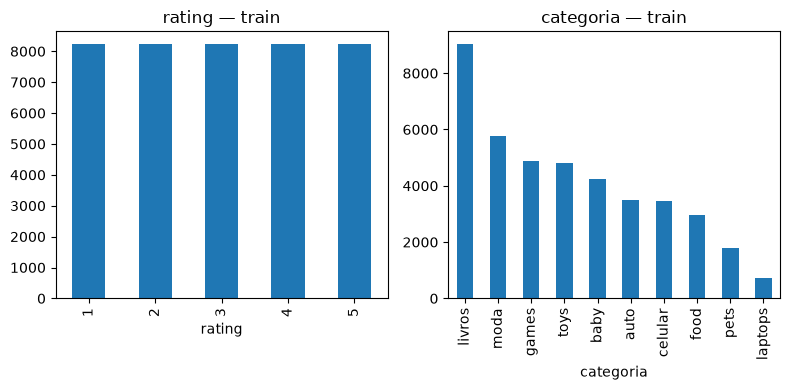

In [4]:
print("rating train:", train["rating"].value_counts().sort_index().to_dict())
print("rating test :", test["rating"].value_counts().sort_index().to_dict())
print("\ncategoria train:", train["categoria"].value_counts().to_dict())
print("categoria test :", test["categoria"].value_counts().to_dict())

fig, ax = plt.subplots(1, 2)
train["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="rating — train")
train["categoria"].value_counts().plot.bar(ax=ax[1], title="categoria — train")
plt.tight_layout()
plt.show()

## 4. Comprimento dos textos + extremos

Motivo: define se a Issue #4/#6 precisa de truncamento ou tratamento para curtíssimos ("Ok", emoji sozinho) e longos (até ~5 mil chars). Reviews negativas tendem a ser mais longas — padrão coerente com o esperado.


train — chars: {'count': 41172.0, 'mean': 121.9, 'std': 131.2, 'min': 0.0, '25%': 43.0, '50%': 86.0, '75%': 156.0, 'max': 4930.0}
train — palavras: {'count': 41172.0, 'mean': 21.4, 'std': 23.0, 'min': 0.0, '25%': 7.0, '50%': 15.0, '75%': 28.0, 'max': 865.0}

test — chars: {'count': 10293.0, 'mean': 118.7, 'std': 125.7, 'min': 0.0, '25%': 42.0, '50%': 83.0, '75%': 154.0, 'max': 4257.0}
test — palavras: {'count': 10293.0, 'mean': 20.9, 'std': 22.2, 'min': 0.0, '25%': 7.0, '50%': 15.0, '75%': 27.0, 'max': 739.0}


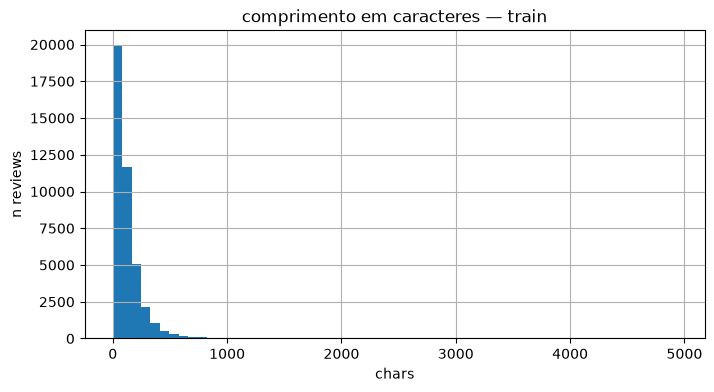


10 mais curtos (train):
  len=   3 cat=moda     rating=5 text=nan
  len=   1 cat=food     rating=3 text='O'
  len=   1 cat=games    rating=4 text='1'
  len=   1 cat=games    rating=3 text='a'
  len=   1 cat=games    rating=1 text='x'
  len=   1 cat=livros   rating=2 text='-'
  len=   1 cat=livros   rating=5 text='.'
  len=   1 cat=celular  rating=2 text='P'
  len=   1 cat=livros   rating=4 text='👍'
  len=   1 cat=baby     rating=4 text='👍'

3 mais longos (train, prefixo):
  len=4930 cat=laptops rating=2 → 'A mídia não pôde ser carregada.EDIT - (após pouco mais de 03 meses de uso);Logo após meu 1º mês de uso, notei que câmera do notebook não funcionava mais, realizei todos os procedimentos no site da fab'...
  len=4886 cat=livros rating=2 → "Existe a salada de frutas e existe este livro que é uma 'salada de assuntos' diversos e complexos e que foram tratados e debatidos pelo autor no decorrer dele. A maioria desses assuntos não atraem a a"...
  len=2680 cat=livros rating=3 → "O conteúd

In [5]:
for nome, df in [("train", train), ("test", test)]:
    s = df["text"].fillna("").astype(str)
    print(f"\n{nome} — chars:", s.str.len().describe().round(1).to_dict())
    print(f"{nome} — palavras:", s.str.split().str.len().describe().round(1).to_dict())

s_train = train["text"].fillna("").astype(str)
s_train.str.len().hist(bins=60)
plt.title("comprimento em caracteres — train")
plt.xlabel("chars");
plt.ylabel("n reviews")
plt.show()

print("\n10 mais curtos (train):")
for i in s_train.str.len().nsmallest(10).index:
    print(f"  len={len(str(train.loc[i, 'text'])):>4} cat={train.loc[i, 'categoria']:<8} rating={train.loc[i, 'rating']} text={train.loc[i, 'text']!r}")
print("\n3 mais longos (train, prefixo):")
for i in s_train.str.len().nlargest(3).index:
    t = str(train.loc[i, "text"])
    print(f"  len={len(t)} cat={train.loc[i, 'categoria']} rating={train.loc[i, 'rating']} → {t[:200]!r}...")

train["w_real"] = s_train.str.split().str.len()
print("\nmedia de palavras por rating (train):", train.groupby("rating")["w_real"].mean().round(1).to_dict())

## 5. Ruídos: HTML, URLs, emojis, emoticons, caracteres repetidos

Motivo: cada achado vira uma decisão da Issue #4. Regex aqui é propositalmente simples — é auditoria, não o normalizador final.

In [6]:
HTML = re.compile(r"<[^>]+>")
URL = re.compile(r"https?://|www\.")
EMOJI = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF]")
EMOTICON = re.compile(r"[:;]-?[)D(PpOo(\]]|XD")
REPETIDO = re.compile(r"(.)\1{2,}")

for nome, df in [("train", train), ("test", test)]:
    s = df["text"].fillna("").astype(str)
    print(f"{nome}: html={int(s.str.contains(HTML, regex=True).sum())} | "
          f"url={int(s.str.contains(URL, regex=True).sum())} | "
          f"emoji={int(s.str.contains(EMOJI, regex=True).sum())} | "
          f"emoticon={int(s.str.contains(EMOTICON, regex=True).sum())} | "
          f"repetidos={int(s.str.contains(REPETIDO, regex=True).sum())}")

print("\nExemplo sinalizado como HTML (falso positivo — teclas de teclado, não HTML real):")
m = train["text"].fillna("").astype(str).str.contains(HTML, regex=True)
print(train.loc[m, "text"].iloc[0][:400])

print("\nExemplos com emoji (train):")
m = train["text"].fillna("").astype(str).str.contains(EMOJI, regex=True)
for t in train.loc[m, "text"].head(3).tolist():
    print(" -", repr(t[:160]))

print("\nExemplos com caracteres repetidos (train):")
m = train["text"].fillna("").astype(str).str.contains(REPETIDO, regex=True)
for t in train.loc[m, "text"].head(3).tolist():
    print(" -", repr(t[:160]))

/tmp/ipykernel_1026977/2230368638.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f"repetidos={int(s.str.contains(REPETIDO, regex=True).sum())}")
/tmp/ipykernel_1026977/2230368638.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f"repetidos={int(s.str.contains(REPETIDO, regex=True).sum())}")
/tmp/ipykernel_1026977/2230368638.py:25: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  m = train["text"].fillna("").astype(str).str.contains(REPETIDO, regex=True)


train: html=1 | url=0 | emoji=446 | emoticon=152 | repetidos=3260
test: html=0 | url=0 | emoji=127 | emoticon=25 | repetidos=845

Exemplo sinalizado como HTML (falso positivo — teclas de teclado, não HTML real):
Comprei para o meu filho e ele me devolveu no primeiro dia. Ele não conseguia usar as teclas <W> e <espaço> ao mesmo tempo (necessário para o personagem pular). Também percebi problemas no acesso aos caracteres que necessitam o uso da tecla <Shift > (alguns só funcionam com a tecla esquerda e outros somente com a direita: abrir parênteses, por exemplo,  somente funciona com o <shift> direito, o qu

Exemplos com emoji (train):
 - 'O livro é simplemente fantástico, um dos melhores que eu já li, ao chegar no final do livro percebi que por erro de impressão algumas páginas se encontravam em '
 - 'Produto chegou em perfeito estado  vamos testar o tempo da bateria mas o produto é muito bom. 👍👍👍'
 - 'Boa qualidade... errei o tamanho hahha mas assim que minha baby crescer, vai usar 💝'


## 6. Acentos e abreviações

Motivo: a Issue #4 já prevê `strip_accent` parametrizável e dicionário de abreviações (`vc`, `pq`, `eh`, `q`, `tá`). Aqui quantificamos para justificar: `não` >> `nao` (unificar via acento faz sentido) e abreviações têm frequência baixa individual, mas somadas reduzem o vocabulário do TF-IDF.

In [7]:
for nome, df in [("train", train), ("test", test)]:
    s = df["text"].fillna("").astype(str).str.lower()
    nao_ac = int(s.str.contains(r"\bnão\b", regex=True).sum())
    nao_no = int(s.str.contains(r"\bnao\b", regex=True).sum())
    print(f"{nome}: 'não'={nao_ac} | 'nao'={nao_no}")
    for w in ["vc", "pq", "eh", "tb", "blz", "q"]:
        n = int(s.str.contains(rf"\b{w}\b", regex=True).sum())
        print(f"  {w}={n}")

print("\nExemplos com 'nao' sem acento:")
m = train["text"].fillna("").astype(str).str.lower().str.contains(r"\bnao\b", regex=True)
for t in train.loc[m, "text"].head(3).tolist():
    print(" -", repr(t[:160]))

train: 'não'=14589 | 'nao'=815
  vc=258
  pq=430
  eh=82


  tb=58
  blz=2
  q=622
test: 'não'=3655 | 'nao'=192
  vc=71
  pq=112
  eh=17
  tb=16


  blz=0
  q=151

Exemplos com 'nao' sem acento:
 - 'O led n funcionou, n troquei porque nao tive tempo'
 - 'Alem de ser muito mais justo do que eu esperava (visto M e comprei G), nao gostei do tecido. O comprimento nao é legal tambem. Rasgou na primeira lavagem.'
 - 'Telefone veio com defeito,nao reconhecia o chip,telefone esquentando e descarregando rápido. Decepcionada .'


## 7. Exemplos antes → depois (proposta para a Issue #4)

Motivo: a Issue #4 implementará `normalize(texto)` em `src/preprocessing/normalization.py`. Aqui registramos exemplos reais e o comportamento **proposto** (simulação com regras simples, sem implementar o módulo final).

In [8]:
def proposta_simples(t: str) -> str:
    """Simulação APENAS para ilustrar a proposta — o normalizador real sai na Issue #4."""
    t = t.lower()
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)  # oooo → oo, !!!! → !!
    t = re.sub(r"\s+", " ", t).strip()
    return t

exemplos = [
    train["text"].dropna().iloc[0],
    "Produto  MUITO   bom!!! Ameiii ooo produto  :)",
    "Nao gostei, vc precisa melhorar pq eh caro",
]
for t in exemplos:
    print("ANTES :", repr(t[:160]))
    print("DEPOIS:", repr(proposta_simples(str(t))[:160]))
    print()

ANTES : 'Ótimo custo benefício, bom café, desde que não supere muito os r$40. Café redondo para o dia a dia, sem convercê de someliê.'
DEPOIS: 'ótimo custo benefício, bom café, desde que não supere muito os r$40. café redondo para o dia a dia, sem convercê de someliê.'

ANTES : 'Produto  MUITO   bom!!! Ameiii ooo produto  :)'
DEPOIS: 'produto muito bom!! ameii oo produto :)'

ANTES : 'Nao gostei, vc precisa melhorar pq eh caro'
DEPOIS: 'nao gostei, vc precisa melhorar pq eh caro'



## 8. Checagem rápida das 58 features (só nulos + coerência)

Motivo: escopo inicial usa TF-IDF sobre `text` (features fora do baseline, reservadas para RQ2/RQ3). Basta garantir que não há nulos e que as contagens batem com o texto real.

In [9]:
print("nulos train:", int(train[FEATURES].isna().sum().sum()))
print("nulos test :", int(test[FEATURES].isna().sum().sum()))

# Coerência: str_qtwords do CSV vs contagem real
w_real = train["text"].fillna("").astype(str).str.split().str.len()
print("corr(str_qtwords, contagem real):", round(train["str_qtwords"].corr(w_real), 4))
print("media de palavras por rating:", train.groupby("rating")["w_real"].mean().round(1).to_dict())

# Incoerência conhecida: linha vazia (NaN) tem features != 0 — registrar, não corrigir aqui
print("\nfeatures da linha vazia (train):")
vazia = train[train["text"].isna()].iloc[0]
print({k: vazia[k] for k in ["str_qtcharacters", "str_qtsentences", "str_qtwords"]})

nulos train: 0
nulos test : 0


corr(str_qtwords, contagem real): 0.9997
media de palavras por rating: {1: 22.4, 2: 25.9, 3: 23.9, 4: 20.6, 5: 14.0}

features da linha vazia (train):
{'str_qtcharacters': np.float64(3.0), 'str_qtsentences': np.float64(1.0), 'str_qtwords': np.float64(1.0)}


## 9. Resumo — problemas encontrados e decisão do que normalizar

| # | Problema | Evidência | Decisão proposta (Issue #4) |
|---|---|---|---|
| 1 | 1 texto vazio por split (`NaN`) | `NaN=1` em train e test; features da linha vazia incoerentes (`str_qtwords=1`) | Remover as 2 linhas (1/41k irrelevante; evita `NaN` no TF-IDF) |
| 2 | Duplicatas por `text` intra-split | train ~2800 linhas em textos repetidos; test ~500 | Manter (repetição natural de reviews curtas); não alterar splits |
| 3 | Overlap train/test | 280 combos distintos (`categoria`,`text`,`rating`) nos dois splits — confere com `data/README.md` | Manter splits oficiais; registrar como limitação na Issue #11 (otimismo artificial) |
| 4 | `rating` balanceado; `categoria` desbalanceada | rating ~8234/classe (train); `livros`=9035 vs `laptops`=740 | Sem ação no texto; considerar estratificação por categoria na modelagem (RQ4) |
| 5 | Extremos de comprimento | mediana ~86 chars/15 palavras; máx ~4930 chars; mínimos de 1 char, só emoji | Sem truncamento nesta etapa; TF-IDF lida com esparsidade; curtíssimos viram vetores quase vazios (aceito) |
| 6 | HTML | 1 caso no train — falso positivo (`<W>`, `<espaço>`, `<Shift>`, teclas de teclado) | **Não** remover tags cegamente; se houver regra, usar lista restrita |
| 7 | URLs | 0 ocorrências | Sem regra de URL (evita código morto) |
| 8 | Emojis (~1%) / emoticons (~0,3%) | 446+127 emojis; 152+25 emoticons | Preservar nesta etapa (carregam polaridade; features `twt_*` usam); normalização decide se converte em token na #4 |
| 9 | Caracteres repetidos (~8%) | 3260 train / 845 test (`oooo`, `!!!`, `hahha`) | Normalizar repetição 3+ → 2 (`ooo`→`oo`) |
| 10 | Acentos inconsistentes | `não`=14589 vs `nao`=815 (train) | `strip_accent` parametrizável unificando (padrão: remover), como já previsto na #4 |
| 11 | Abreviações | `vc`, `pq`, `eh`, `tb`, `q` presentes em baixa frequência individual | Dicionário pequeno de expansão (`vc`→`você`, `pq`→`porque`, `eh`→`é`, `tb`→`também`) |
| 12 | Caixa alta / espaços | Comentários com MAIÚSCULAS e espaços múltiplos | Minúsculas + colapso de espaços (padrão do TF-IDF) |
| 13 | 58 features | 0 nulos; `corr(str_qtwords, real)=~0.999` | Coerentes; fora do baseline TF-IDF (RQ2/RQ3) |

**Critérios de conclusão atendidos:** notebook executável e versionado aqui; quantidades acima documentadas; decisão do que normalizar registrada na tabela.